# J04 — Model-data comparison: GENIE paleo-SST against DeepMIP proxy sites reconstructed with GPlately

**Cluster J: Paleoclimate.**
**Compare the sea-surface temperature of a PLASIM-GENIE Earth-system-model simulation at 50 Ma with the DeepMIP compilation of early Eocene Climatic Optimum (EECO) proxy SSTs, after reconstructing every proxy site with the same plate model and reference frame as the model's paleogeography.**

## What this notebook produces

PLASIM-GENIE couples the PLASIM atmosphere to the GOLDSTEIN ocean and sea-ice of the GENIE Earth-system-model framework (Holden et al. 2016). It runs at coarse resolution (64 × 32 cells) on paleogeographic boundary conditions. Leonard et al. (2025) ran it every 10 Myr since 250 Ma on paleogeographies built in four reference frames; this notebook uses the 50 Ma run in the Merdith et al. (2021) paleomagnetic frame, which combines the relative plate motions of Zahirovic et al. (2022) with anchor plate 701701.

The proxies are the DeepMIP compilation of Hollis et al. (2019): SST estimates from TEX86, Mg/Ca, foraminiferal δ18O and clumped isotopes (Δ47) for the EECO (53.3-49.1 Ma), each with its uncertainty.

1. Load the model SST field and the EECO SST estimates.
2. Reconstruct each proxy site to 50 Ma with the Zahirovic 2022 model in the 701701 paleomagnetic frame — the plate model and frame of the simulation.
3. Plot the proxies at their paleo-positions, coloured by observed SST, on the model field.
4. Sample the model at each site and map the residual (model − proxy).
5. Compare proxy SST with the model's zonal-mean SST against paleo-latitude.

**Audience**: postgrad.
**Difficulty**: ★★★.

## Learning objectives

- Load an Earth-system-model ocean field with xarray and render it with `pygmt.grdimage`.
- Reconstruct a population of proxy sites to a target model age with `gplately`, in the same plate model and reference frame as the model boundary conditions.
- Compute model-data residuals at scattered observation locations on a coarse model grid.
- Read a meridional SST gradient comparison, the standard DeepMIP diagnostic.

## Prerequisites and runtime

- Plate model: Zahirovic 2022, paleomagnetic frame (anchor plate 701701).
- Data: `data/paleoceanography/` (48 KB), built by `tools/build_paleoceanography_j04.py`.
- Python: `gplately`, `pygmt`, `pygplates`, `xarray`, `numpy`, `pandas`.
- Runtime: \~30 s.


## Data availability

1. **`data/paleoceanography/genie_sst_50Ma_leonard2025.nc`** — annual-mean SST (top ocean layer, 0-81 m) of the 50 Ma PLASIM-GENIE simulation of Leonard et al. (2025) in the Merdith 2021 paleomagnetic frame, extracted from their Zenodo archive (https://doi.org/10.5281/zenodo.15628277, CC BY 4.0). Land cells are empty.

2. **`data/paleoceanography/deepmip_hollis2019_compilation.csv`** — the DeepMIP site compilation of Hollis et al. (2019) of sea-surface and land-air temperatures for the latest Paleocene, the PETM and the EECO, as distributed in the supplement of Inglis et al. (2020) (CC BY 4.0). Each row is one estimate: site, time slice, `sst` or `lat` (land air temperature), proxy, modern coordinates, the median (`50`) with uncertainty bounds, and flags `v1`-`v5` for the subsets used by Inglis et al. (2020). Missing values are −999.9.


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd, xarray as xr
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
import sys as _sys
from pathlib import Path as _P
for _d in (_P("Notebooks"), _P("."), _P("../Notebooks")):
    if (_d / "pmm_local.py").exists():
        _sys.path.insert(0, str(_d.resolve())); break
from pmm_local import LocalFirstPMM   # uses the local cache if the model server is unreachable
print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")


gplately 2.0.0  pygmt v0.19.0  pygplates 1.0.0


## Configuration — change the proxy subset and the model age here

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME       = "Zahirovic2022"   # relative plate motions of the Leonard et al. (2025) simulations
ANCHOR_PLATE_ID  = 701701            # Merdith 2021 paleomagnetic frame, as in the simulation
MODEL_SST_NC     = "data/paleoceanography/genie_sst_50Ma_leonard2025.nc"
PROXY_CSV        = "data/paleoceanography/deepmip_hollis2019_compilation.csv"
SNAPSHOT_AGE_MA  = 50.0              # age of the simulation's paleogeography
TIMESLICE        = "eeco"            # DeepMIP time slice: eeco (53.3-49.1 Ma), petm or lp
DEEPMIP_SUBSET   = "v1"              # v2 = all estimates; v1 = without recrystallised planktonic
                                     # foraminiferal δ18O (Inglis et al. 2020)
SST_RANGE_C      = (0, 40)           # min, max of the SST colour bar
# ============================================================================

## 1. Load the model SST field and the DeepMIP proxy estimates

In [3]:
sst = xr.open_dataset(MODEL_SST_NC)["sst"]
deepmip = pd.read_csv(PROXY_CSV, na_values=[-999.9])
proxy = deepmip[(deepmip["timeslice"] == TIMESLICE) & (deepmip["temperature"] == "sst")
                & (deepmip[DEEPMIP_SUBSET] == 1)].copy()
# The δ18O row of Hampden Beach gives longitude 107.83; its Mg/Ca and TEX86 rows, and its
# paleo-longitude in the compilation, place the site at 170.83 E (New Zealand).
proxy.loc[(proxy["site"] == "hampden beach") & (proxy["lon"] == 107.83), "lon"] = 170.83
proxy = proxy.rename(columns={"50": "sst_C", "deepmip lower error": "sst_lo_C", "deepmip upper error": "sst_hi_C"})
proxy = proxy[["site", "proxy", "lat", "lon", "sst_C", "sst_lo_C", "sst_hi_C"]].reset_index(drop=True)

print(f"  model SST grid: {dict(sst.sizes)}, {float(sst.min()):.1f} to {float(sst.max()):.1f} °C, "
      f"{int(sst.notnull().sum())} ocean cells")
print(f"  DeepMIP {TIMESLICE.upper()} SST estimates ({DEEPMIP_SUBSET}): {len(proxy)} from {proxy['site'].nunique()} sites")
print("  by proxy:", proxy["proxy"].value_counts().to_dict())
proxy.head()

  model SST grid: {'lat': 32, 'lon': 64}, -0.8 to 36.9 °C, 1323 ocean cells
  DeepMIP EECO SST estimates (v1): 27 from 21 sites
  by proxy: {'tex86': 11, 'mgca': 6, 'del18O': 5, 'del47': 5}


,site,proxy,lat,lon,sst_C,sst_lo_C,sst_hi_C
0,hampden beach,del18O,-45.32,170.83,18.77,18.07,19.54
1,lodo gulch,del18O,36.59,-120.64,19.06,17.46,20.24
2,midwaipara,del18O,-43.06,172.61,28.36,23.51,33.48
3,tanzania,del18O,-8.85,39.63,29.63,28.27,30.96
4,wilson lake,del18O,39.66,-75.04,23.57,NaN,NaN


## 2. Reconstruct the proxy sites to the model age

In [4]:
pmm   = LocalFirstPMM()
model = pmm.get_model(MODEL_NAME, data_dir="data/pmm_cache")
recon = gplately.PlateReconstruction(
    rotation_model=model.get_rotation_model(),
    topology_features=model.get_topologies(),
    static_polygons=model.get_static_polygons(),
    anchor_plate_id=ANCHOR_PLATE_ID,
)
gplot = gplately.PlotTopologies(
    plate_reconstruction=recon,
    coastlines=model.get_coastlines(),
    continents=model.get_continental_polygons(),
    time=SNAPSHOT_AGE_MA,
    anchor_plate_id=ANCHOR_PLATE_ID,
    plot_engine=gplately.PygmtPlotEngine(),
)
pts = gplately.Points(recon, proxy["lon"].values, proxy["lat"].values, anchor_plate_id=ANCHOR_PLATE_ID)
rlon, rlat = pts.reconstruct(SNAPSHOT_AGE_MA, anchor_plate_id=ANCHOR_PLATE_ID, return_array=True)
proxy["paleo_lon"], proxy["paleo_lat"] = rlon, rlat
print(f"  reconstructed {len(proxy)} estimates to {SNAPSHOT_AGE_MA:.0f} Ma "
      f"(paleo-latitudes {proxy['paleo_lat'].min():.0f} to {proxy['paleo_lat'].max():.0f})")

  reconstructed 27 estimates to 50 Ma (paleo-latitudes -59 to 50)


## 3. Render: model field + proxy points at their paleo-positions

The model field is drawn cell by cell at its native resolution (5.6° × \~5.5°); white cells are land in the model. Grey outlines are the 50 Ma continental polygons of the plate model. Proxy symbols are coloured by observed SST on the same colour scale as the model, so a symbol that disappears into the field is a site where model and proxy agree.

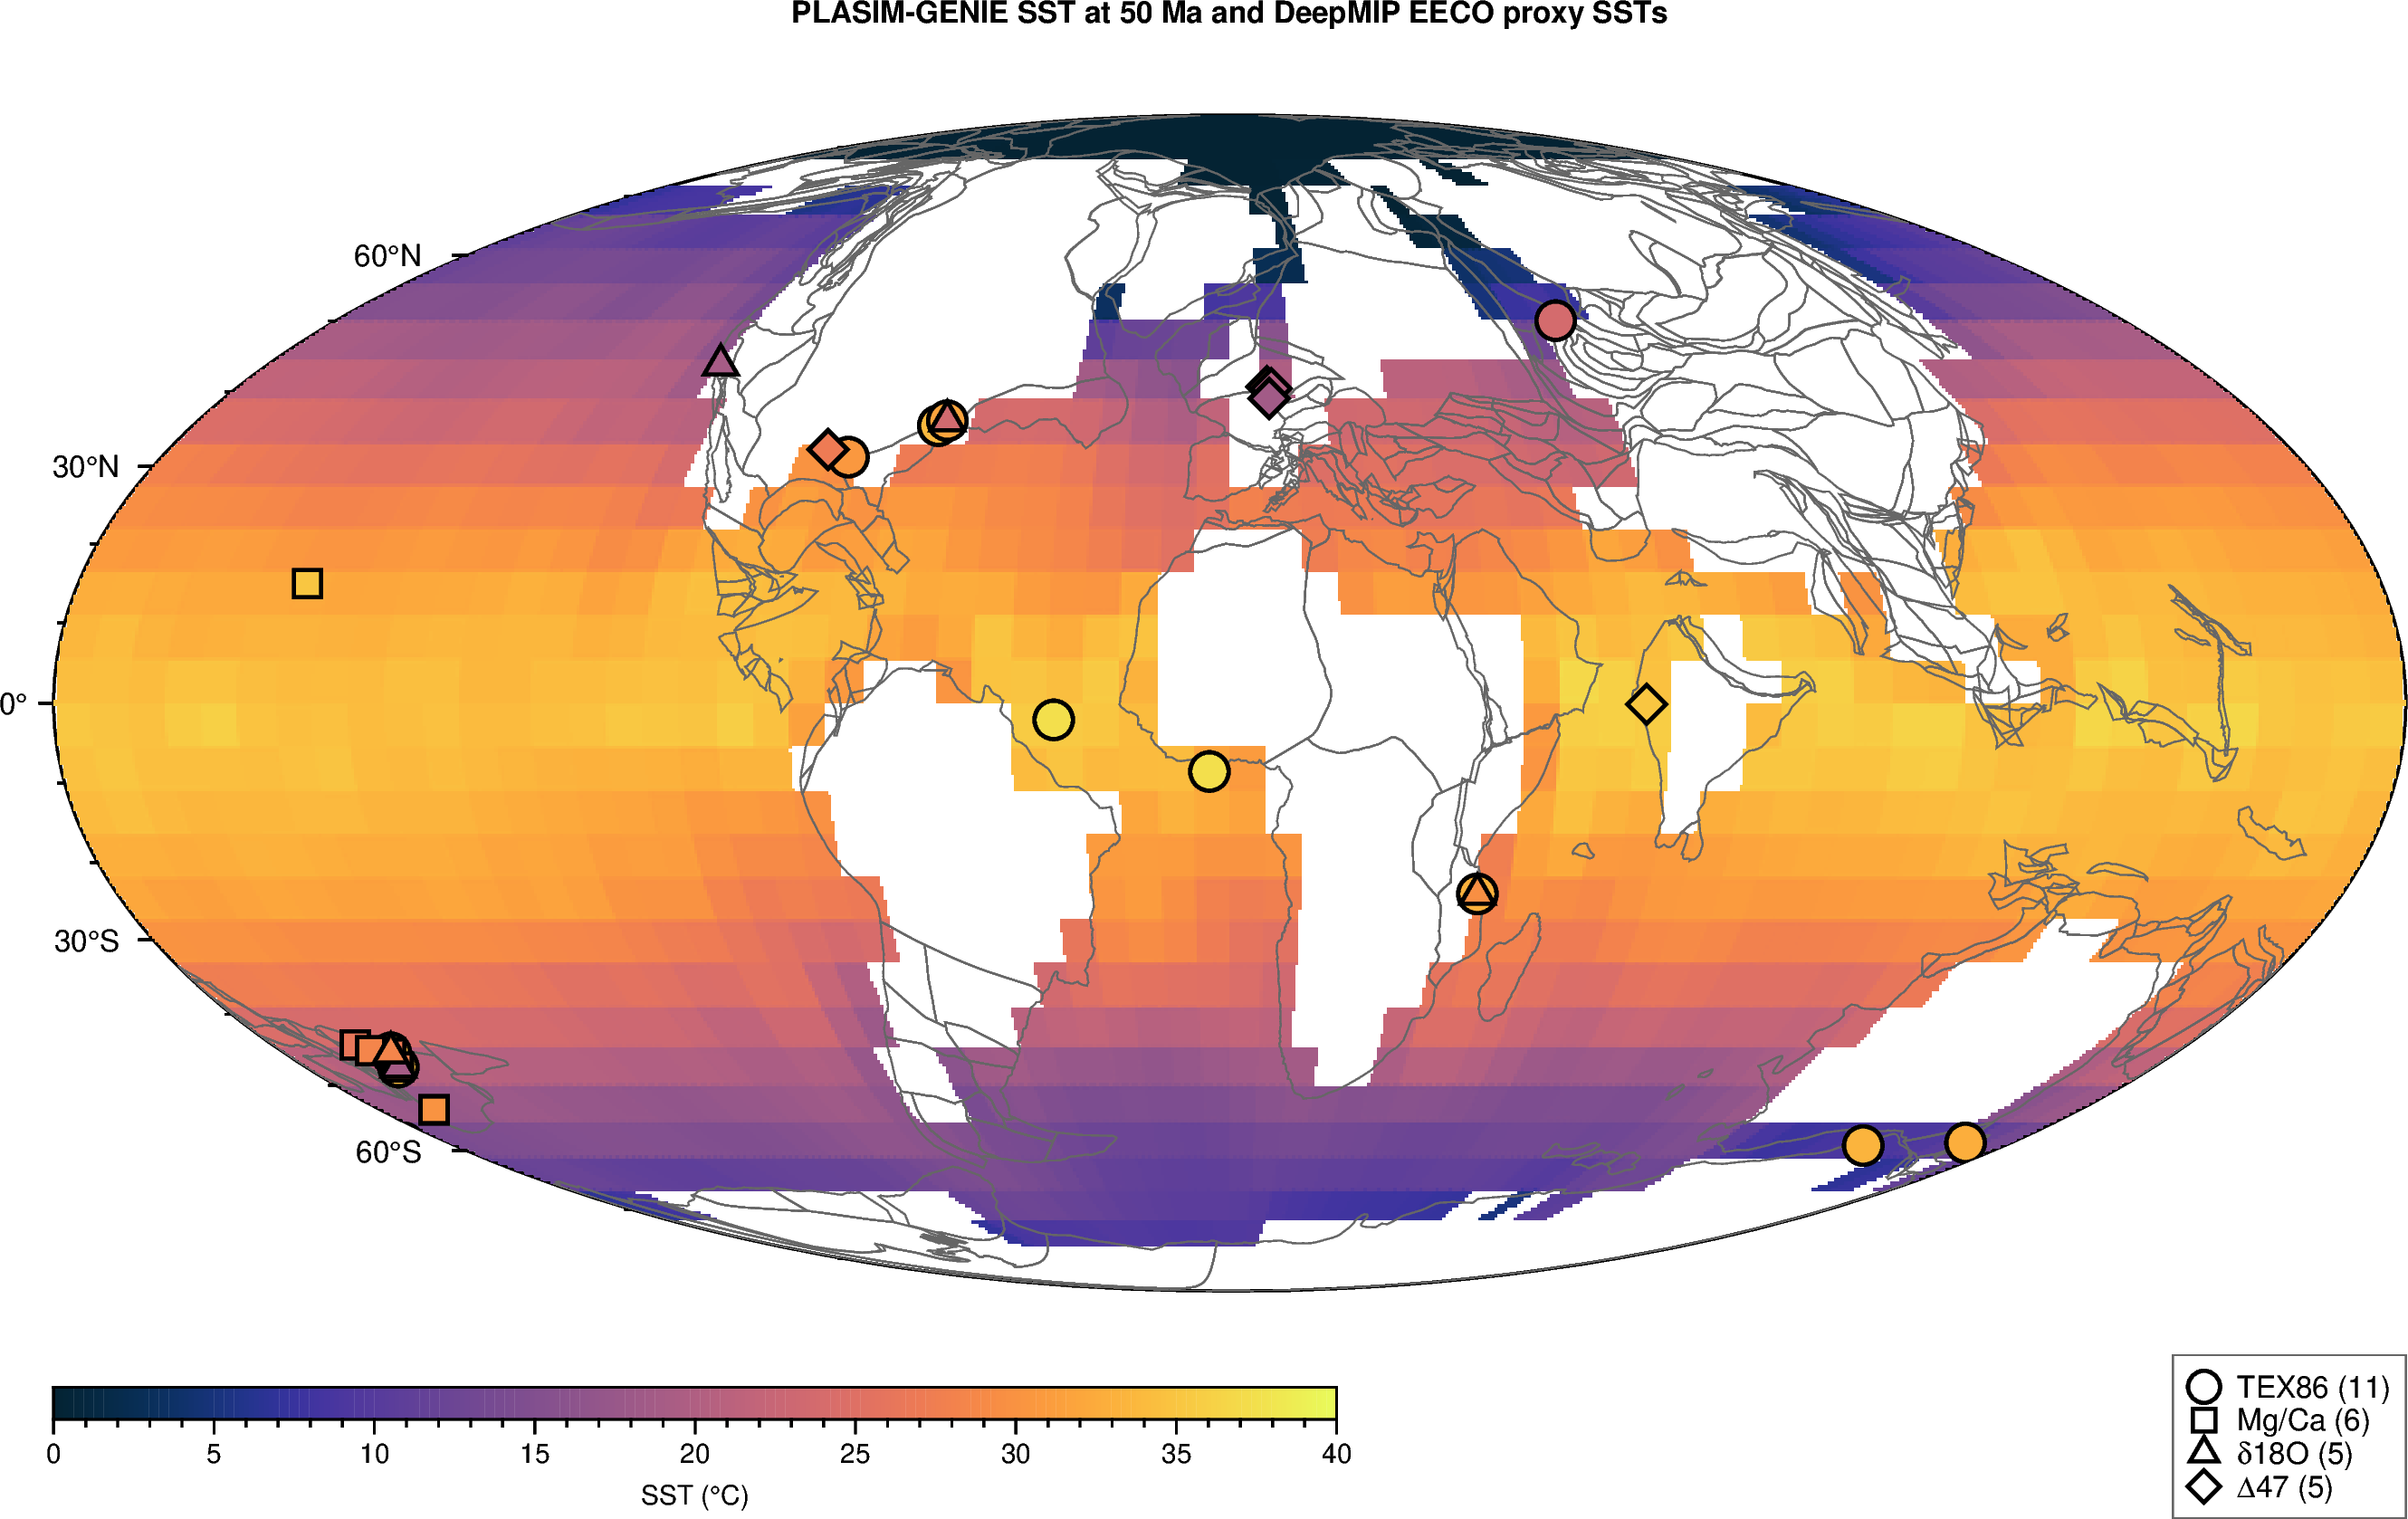

In [5]:
# Nearest-cell resampling to 0.5° keeps the model cells visible (display only)
fine = sst.interp(lat=np.arange(-89.75, 90, 0.5), lon=np.arange(-179.75, 180, 0.5), method="nearest",
                  kwargs={"fill_value": "extrapolate"})
SYMBOL = {"tex86": "c", "mgca": "s", "del18O": "t", "del47": "d"}
LABEL  = {"tex86": "TEX86", "mgca": "Mg/Ca", "del18O": "δ18O", "del47": "@~D@~47"}   # @~D@~: GMT escape for the Greek capital delta

fig = pygmt.Figure()
fig.basemap(region="d", projection="W0/22c",
            frame=["af", f"+tPLASIM-GENIE SST at {SNAPSHOT_AGE_MA:.0f} Ma and DeepMIP {TIMESLICE.upper()} proxy SSTs"])
pygmt.makecpt(cmap="thermal", series=list(SST_RANGE_C[:2]), background="o")
fig.grdimage(fine, cmap=True, nan_transparent=True)
gplot.plot_continents(fig, pen="0.4p,gray40")
for prox, sym in SYMBOL.items():
    sub = proxy[proxy["proxy"] == prox]
    if len(sub):
        fig.plot(x=sub["paleo_lon"], y=sub["paleo_lat"], style=f"{sym}0.36c", fill=sub["sst_C"], cmap=True,
                 pen="1.0p,black")
        fig.plot(x=[np.nan], y=[np.nan], style=f"{sym}0.3c", fill="white", pen="1p,black",
                 label=f"{LABEL[prox]} ({len(sub)})")
fig.legend(position="JBR+jTR+o0/0.6c", box="+gwhite+p0.5p,gray40")
fig.colorbar(frame="af+lSST (°C)", position="JBL+jTL+w12c/0.3c+h+o0/0.9c")
fig.show(width=1100)

## 4. Per-site model − proxy residual map

The model is sampled in the ocean cell nearest to each reconstructed site: on a 5.6° grid a coastal site often falls in a model land cell. The distance to that cell is reported.

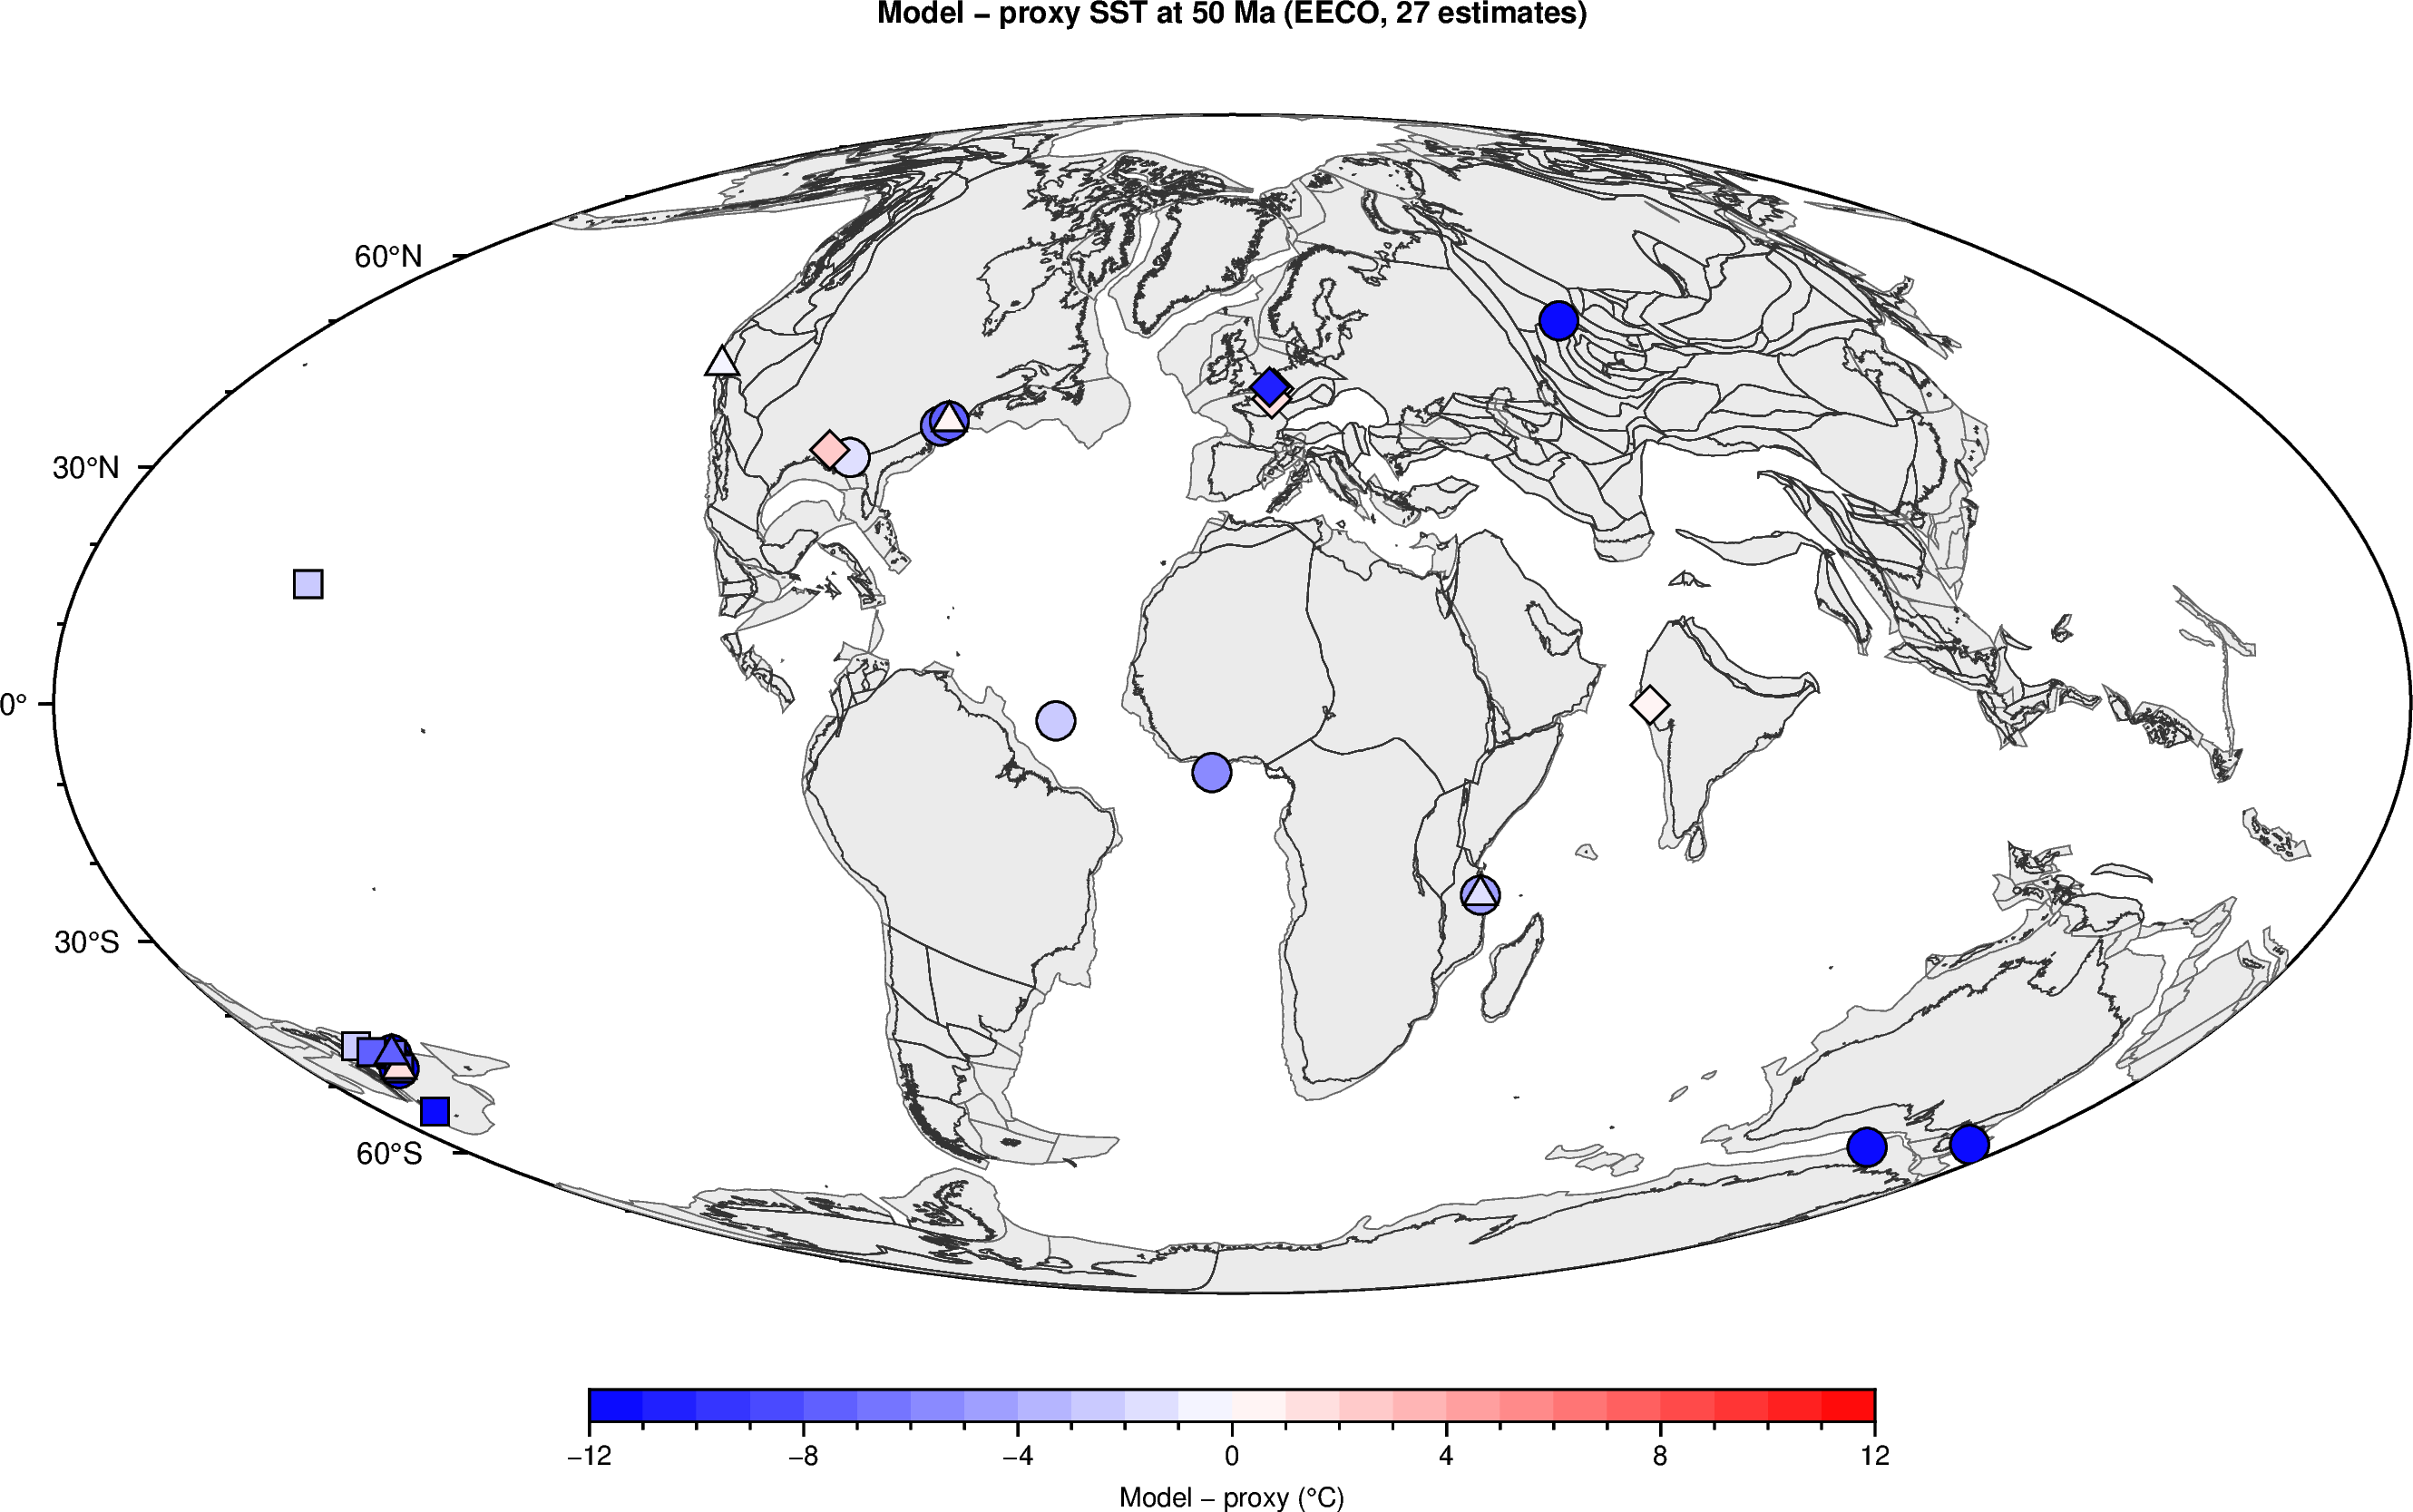

  mean residual -6.3 °C (σ = 7.0 °C); median distance to the sampled model cell 200 km


,site,proxy,paleo_lat,sst_C,sst_model_C,residual_C
18,iodp 1356,tex86,-59.2,33.4,9.0,-24.4
20,odp 1172,tex86,-58.7,32.8,11.9,-20.8
10,dsdp 277,mgca,-53.7,30.1,17.4,-12.7
0,hampden beach,del18O,-47.4,18.8,20.5,1.7
11,hampden beach,mgca,-47.4,27.8,20.5,-7.4
16,hampden beach,tex86,-47.4,34.5,20.5,-14.0
12,midwaipara,mgca,-45.3,27.1,20.5,-6.6
2,midwaipara,del18O,-45.3,28.4,20.5,-7.9
19,midwaipara,tex86,-45.3,34.5,20.5,-14.0
15,tora,mgca,-45.1,28.4,20.5,-7.9


In [6]:
ocean = sst.to_dataframe().dropna().reset_index()          # one row per ocean cell
def nearest_ocean(lon, lat):
    """SST of the nearest model ocean cell and its great-circle distance (km)."""
    p1, p2 = np.radians(lat), np.radians(ocean["lat"].values)
    dl = np.radians(ocean["lon"].values - lon)
    d = 6371.0 * np.arccos(np.clip(np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl), -1, 1))
    i = int(np.argmin(d))
    return float(ocean["sst"].iloc[i]), float(d[i])

sampled = [nearest_ocean(lo, la) for lo, la in zip(proxy["paleo_lon"], proxy["paleo_lat"])]
proxy["sst_model_C"], proxy["model_cell_km"] = np.array(sampled).T
proxy["residual_C"] = proxy["sst_model_C"] - proxy["sst_C"]

fig = pygmt.Figure()
fig.basemap(region="d", projection="W0/22c",
            frame=["af", f"+tModel − proxy SST at {SNAPSHOT_AGE_MA:.0f} Ma ({TIMESLICE.upper()}, {len(proxy)} estimates)"])
gplot.plot_continents(fig, fill="gray92", pen="0.3p,gray40")
gplot.plot_coastlines(fig, pen="0.35p,gray20")
pygmt.makecpt(cmap="polar", series=[-12, 12, 1], background="o")
order = proxy["residual_C"].abs().sort_values().index
for prox, sym in SYMBOL.items():
    sub = proxy.loc[order][proxy.loc[order, "proxy"] == prox]
    if len(sub):
        fig.plot(x=sub["paleo_lon"], y=sub["paleo_lat"], style=f"{sym}0.36c", fill=sub["residual_C"],
                 cmap=True, pen="0.6p,black")
fig.colorbar(frame="a4f1+lModel − proxy (°C)", position="JBC+w12c/0.3c+h+o0/0.9c")
fig.show(width=1100)

print(f"  mean residual {proxy['residual_C'].mean():+.1f} °C (σ = {proxy['residual_C'].std():.1f} °C); "
      f"median distance to the sampled model cell {proxy['model_cell_km'].median():.0f} km")
proxy[["site", "proxy", "paleo_lat", "sst_C", "sst_model_C", "residual_C"]].sort_values("paleo_lat").round(1)

## 5. Meridional SST gradient

Proxy SST against paleo-latitude, with error bars from the DeepMIP uncertainty bounds, over the model's zonal-mean SST and the range of its SST at each latitude. This is the standard DeepMIP diagnostic: models of the early Eocene have tended to produce a steeper equator-to-pole gradient than the proxies (Lunt et al. 2021).

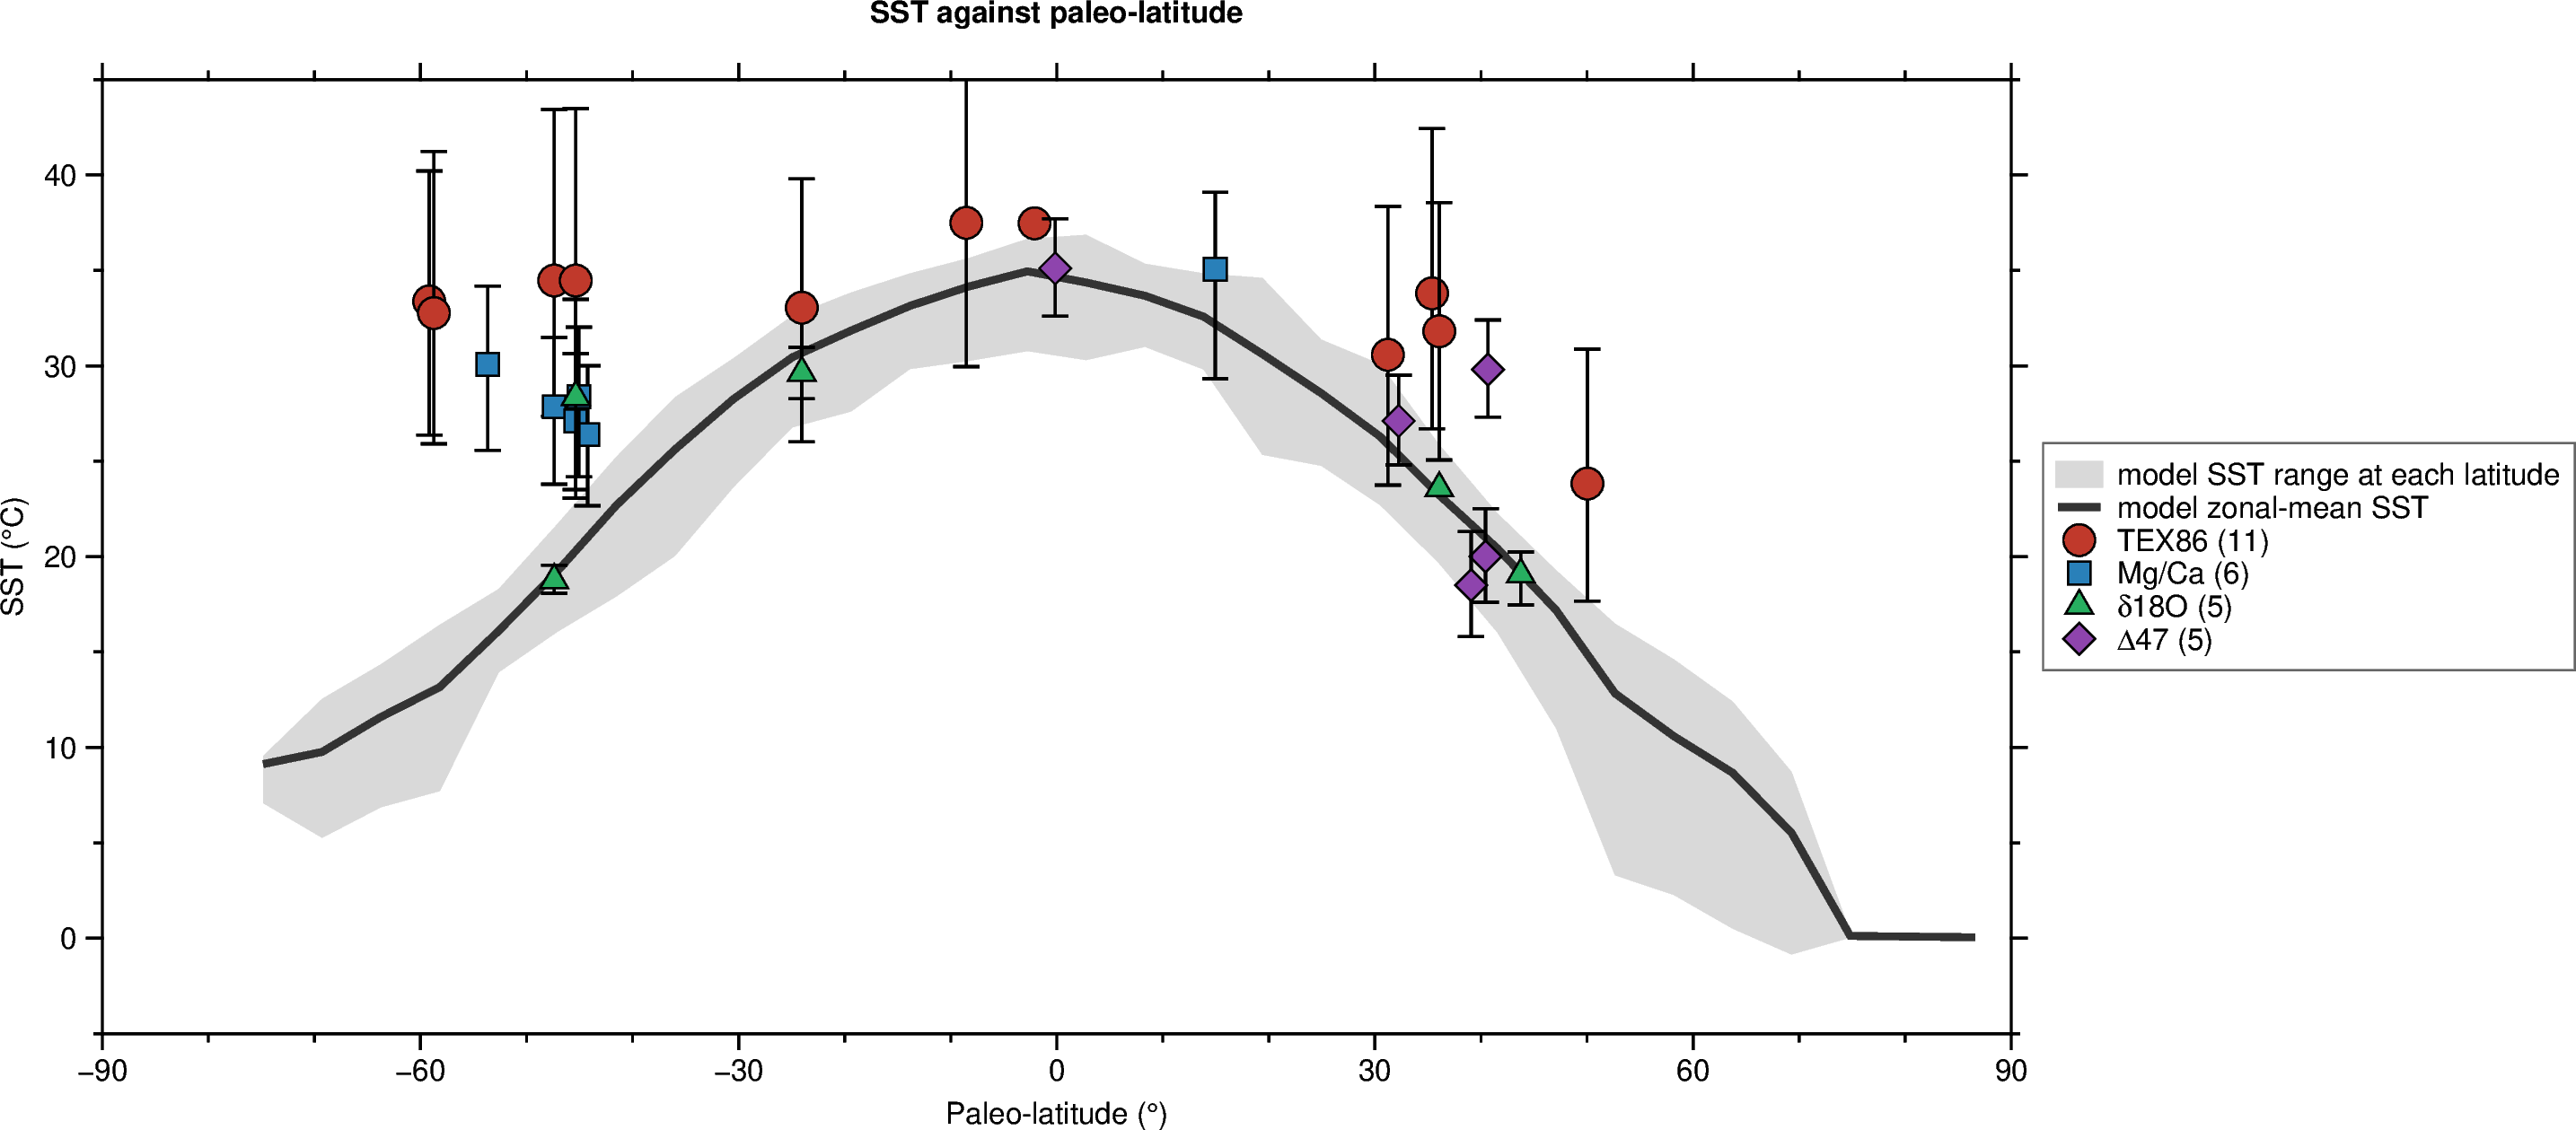

In [7]:
zonal = sst.mean("lon")
fig = pygmt.Figure()
fig.basemap(region=[-90, 90, -5, 45], projection="X18c/9c",
            frame=["WSne+tSST against paleo-latitude", "xa30f10+lPaleo-latitude (°)", "ya10f5+lSST (°C)"])
lat_band = np.concatenate([sst["lat"].values, sst["lat"].values[::-1]])
band = np.concatenate([sst.min("lon").values, sst.max("lon").values[::-1]])
ok = np.isfinite(band)
fig.plot(x=lat_band[ok], y=band[ok], fill="gray85", close=True, label="model SST range at each latitude")
fig.plot(x=zonal["lat"], y=zonal.values, pen="2p,gray20", label="model zonal-mean SST")
COLOUR = {"tex86": "#c0392b", "mgca": "#2980b9", "del18O": "#27ae60", "del47": "#8e44ad"}
for prox, sym in SYMBOL.items():
    sub = proxy[proxy["proxy"] == prox]
    if not len(sub):
        continue
    err = np.c_[sub["sst_C"] - sub["sst_lo_C"], sub["sst_hi_C"] - sub["sst_C"]]
    has = np.isfinite(err).all(axis=1)
    if has.any():                    # estimates with uncertainty bounds: asymmetric error bars
        fig.plot(data=np.c_[sub["paleo_lat"][has], sub["sst_C"][has], err[has]], style=f"{sym}0.3c",
                 fill=COLOUR[prox], pen="0.5p,black", error_bar="y+a+p0.8p")
    if (~has).any():                 # estimates reported without bounds
        fig.plot(x=sub["paleo_lat"][~has], y=sub["sst_C"][~has], style=f"{sym}0.3c", fill=COLOUR[prox],
                 pen="0.5p,black")
    fig.plot(x=[np.nan], y=[np.nan], style=f"{sym}0.3c", fill=COLOUR[prox], pen="0.5p,black",
             label=f"{LABEL[prox]} ({len(sub)})")
fig.legend(position="JMR+jML+o0.3c/0c", box="+gwhite+p0.5p,gray40")
fig.show(width=1000)

## What the figures show

- **§3 and §4** — red residuals mean the model is warmer than the proxy, blue that it is colder. With the default settings the model is colder than most proxies (mean residual about −6 °C). The largest misfits are at the southwest Pacific and Antarctic margin sites (paleo-latitudes 45-60° S), where TEX86 and Mg/Ca give 27-35 °C and the model 9-21 °C, and at the Siberian site. Between about 30° S and 45° N the model is within a few degrees of most estimates.
- **§5** — the proxies define a flatter equator-to-pole gradient than the model: at low latitudes they sit on or slightly above the model's zonal mean, at high southern latitudes far above even the warmest model cells. This is the same pattern DeepMIP found across its model ensemble (Lunt et al. 2021).

Both the model and the proxies carry large uncertainties: the proxy bounds are often ±4-8 °C, the TEX86 calibration is debated at high temperatures, and a model run at one CO2 level and on one paleogeography cannot represent the whole EECO. The point of this notebook is the workflow: proxy sites must be placed with the same plate model and reference frame as the model's boundary conditions before they can be compared.


## Extend this

- **Another reference frame.** Leonard et al. (2025) ran the same model on paleogeographies in the Müller et al. (2016) mantle frame (anchor 705705) and others (notebook J07). Extract that run with `tools/build_paleoceanography_j04.py` and reconstruct the proxies with the matching anchor to see how much the frame alone changes the comparison.
- **Other time slices and subsets.** Set `TIMESLICE = "petm"` or `"lp"`, or `DEEPMIP_SUBSET = "v2"` to include the recrystallised foraminiferal δ18O estimates, which are colder than the other proxies.
- **Land temperatures.** The compilation also holds land air temperatures (`temperature == "lat"`), to compare with the model's surface air temperature (`puma_temperature_surface_air` in the PLASIM output of the same archive).

## References

- Leonard, J., Zahirovic, S., Holden, P.B., Salles, T., Edwards, N.R. & Mallard, C.A. (2025). Polar wander leads to large differences in past climate reconstructions. *Communications Earth & Environment* 6, 508. https://doi.org/10.1038/s43247-025-02485-w — data: https://doi.org/10.5281/zenodo.15628277
- Holden, P.B., Edwards, N.R., Fraedrich, K., Kirk, E., Lunkeit, F. & Zhu, X. (2016). PLASIM-GENIE v1.0: a new intermediate complexity AOGCM. *Geoscientific Model Development* 9, 3347-3361. https://doi.org/10.5194/gmd-9-3347-2016
- Hollis, C.J., Dunkley Jones, T., Anagnostou, E., Bijl, P.K., Cramwinckel, M.J., Cui, Y., Dickens, G.R., Edgar, K.M., Eley, Y., Evans, D., Foster, G.L., Frieling, J., Inglis, G.N., Kennedy, E.M., Kozdon, R., Lauretano, V., Lear, C.H., Littler, K., Lourens, L., Meckler, A.N., Naafs, B.D.A., Pälike, H., Pancost, R.D., Pearson, P.N., Röhl, U., Royer, D.L., Salzmann, U., Schubert, B.A., Seebeck, H., Sluijs, A., Speijer, R.P., Stassen, P., Tierney, J., Tripati, A., Wade, B., Westerhold, T., Witkowski, C., Zachos, J.C., Zhang, Y.G., Huber, M. & Lunt, D.J. (2019). The DeepMIP contribution to PMIP4: methodologies for selection, compilation and analysis of latest Paleocene and early Eocene climate proxy data, incorporating version 0.1 of the DeepMIP database. *Geoscientific Model Development* 12, 3149-3206. https://doi.org/10.5194/gmd-12-3149-2019
- Inglis, G.N., Bragg, F., Burls, N.J., Cramwinckel, M.J., Evans, D., Foster, G.L., Huber, M., Lunt, D.J., Siler, N., Steinig, S., Tierney, J.E., Wilkinson, R., Anagnostou, E., de Boer, A.M., Dunkley Jones, T., Edgar, K.M., Hollis, C.J., Hutchinson, D.K. & Pancost, R.D. (2020). Global mean surface temperature and climate sensitivity of the early Eocene Climatic Optimum (EECO), Paleocene-Eocene Thermal Maximum (PETM), and latest Paleocene. *Climate of the Past* 16, 1953-1968. https://doi.org/10.5194/cp-16-1953-2020
- Lunt, D.J., Bragg, F., Chan, W.-L., Hutchinson, D.K., Ladant, J.-B., Morozova, P., Niezgodzki, I., Steinig, S., Zhang, Z., Zhu, J., Abe-Ouchi, A., Anagnostou, E., de Boer, A.M., Coxall, H.K., Donnadieu, Y., Foster, G., Inglis, G.N., Knorr, G., Langebroek, P.M., Lear, C.H., Lohmann, G., Poulsen, C.J., Sepulchre, P., Tierney, J.E., Valdes, P.J., Volodin, E.M., Dunkley Jones, T., Hollis, C.J., Huber, M. & Otto-Bliesner, B.L. (2021). DeepMIP: model intercomparison of early Eocene climatic optimum (EECO) large-scale climate features and comparison with proxy data. *Climate of the Past* 17, 203-227. https://doi.org/10.5194/cp-17-203-2021
- Merdith, A.S., Williams, S.E., Collins, A.S., Tetley, M.G., Mulder, J.A., Blades, M.L., Young, A., Armistead, S.E., Cannon, J., Zahirovic, S. & Müller, R.D. (2021). Extending full-plate tectonic models into deep time: Linking the Neoproterozoic and the Phanerozoic. *Earth-Science Reviews* 214, 103477. https://doi.org/10.1016/j.earscirev.2020.103477
- Zahirovic, S., Eleish, A., Doss, S., Pall, J., Cannon, J., Pistone, M., Tetley, M.G., Young, A. & Fox, P. (2022). Subduction and carbonate platform interactions. *Geoscience Data Journal* 9(2), 371-383. https://doi.org/10.1002/gdj3.146
- Mather, B.R. et al. (2024). GPlately. *Geoscience Data Journal* 11, 3-10.
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556-5564. https://doi.org/10.1029/2019GC008515